check_event  : Everything looks fine...
[2457205.21, 0.309, 10.7821, 1.3, 0.001, 1.9, np.float64(10000.0), np.float64(12000.0)]


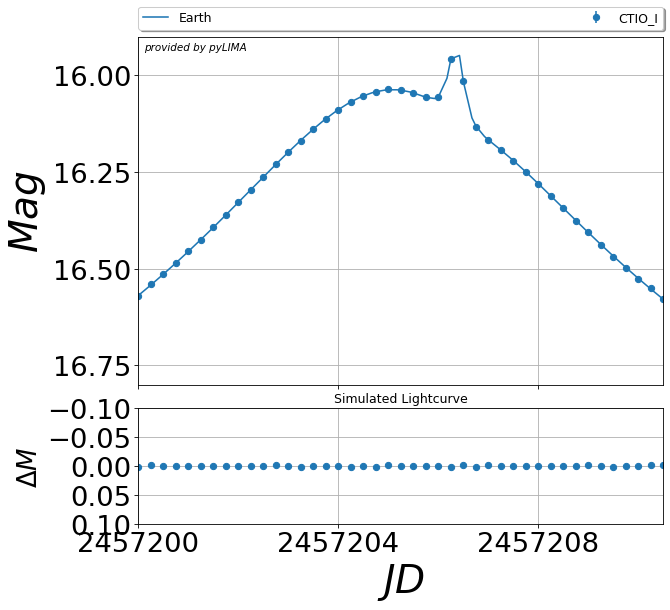

In [1]:
from pyLIMA import event
from pyLIMA.simulations import simulator
from pyLIMA.fits import TRF_fit
from pyLIMA.models import PSBL_model
from pyLIMA.outputs import pyLIMA_plots
import numpy as np
import matplotlib.pyplot as plt

# Create simulated Microlensing event
event_3 = event.Event(ra=270, dec=0)
event_3.name = 'My simulated event'

CTIO_I = simulator.simulate_a_telescope(name='CTIO_I', time_start=2457190, time_end=2457220, sampling=6, 
                                        location='Earth', camera_filter='I',
                                        uniform_sampling=True, astrometry=False)
# LCO_SAAO = simulator.simulate_a_telescope(name='LCO_SAAO', time_start=2457205, time_end=2457208, sampling=1, 
#                                         location='Earth', camera_filter='I',
#                                         uniform_sampling=True, astrometry=False)

event_3.telescopes.append(CTIO_I)
# event_3.telescopes.append(LCO_SAAO)
event_3.check_event()

psbl_sim = PSBL_model.PSBLmodel(event_3)
psbl_sim_params = simulator.simulate_microlensing_model_parameters(psbl_sim)

### Set the parameters to some reasonable values.
psbl_sim_params[0] = 2457205.21 # t0
psbl_sim_params[1:3] = [0.309, 10.7821] # u0, tE
psbl_sim_params[3:6] = [1.3, 0.001, 1.9] # s, q, alpha

### Set the source and blend fluxes of all telescopes to the same values for plotting purposes.
n_tel = len(event_3.telescopes)
psbl_sim_params[-n_tel*2::2] = 10000. * np.ones(n_tel) # source fluxes
psbl_sim_params[-n_tel*2+1::2] = 12000. * np.ones(n_tel) # total fluxes
print(psbl_sim_params)

### Transform the parameters into a pyLIMA class object.
pyLIMA_parameters_1 = psbl_sim.compute_pyLIMA_parameters(psbl_sim_params)

### Inject everthing into the simulator to produce a light curve.
simulator.simulate_lightcurve(psbl_sim, pyLIMA_parameters_1)

pyLIMA_plots.plot_lightcurves(psbl_sim, psbl_sim_params)
plt.title('Simulated Lightcurve')
plt.gcf().axes[0].set_xlim(2457200.0, 2457210.5)
plt.gcf().axes[0].set_ylim(16.8, 15.9)
plt.show()

Selecting CTIO_I to estimate u0, tE and fs
initial_guess  : Initial parameters guess SUCCESS
Using guess:  [2457205.2499999995, 0.4746548726557768, 5.500000000465661, 18645.771479365103, 14323.805372095487]
Trust Region Reflective fit SUCCESS
best model:
OrderedDict([('t0', np.float64(2457205.192023191)),
             ('u0', np.float64(0.315907437679635)),
             ('tE', np.float64(10.701391113352079)),
             ('fsource_CTIO_I', np.float64(10139.962081614616)),
             ('ftotal_CTIO_I', np.float64(12009.25798781092)),
             ('soft_l1', np.float64(725.4486270852207))])


/home/jakob/projects/pyLIMA-docs-revisit/my_project/planet_anomaly_map/planet_anomaly_map.py:83: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


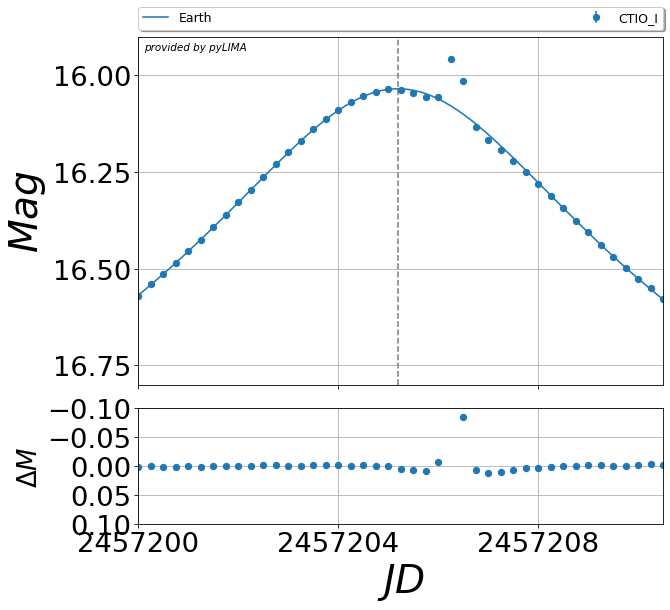

In [2]:
from planet_anomaly_map import PlanetAnomalyMap

anomaly = PlanetAnomalyMap(event=event_3, 
                       window_limits=((2457200.0, 2457210.5),(16.8, 15.9)))

anomaly.run_pspl_fit()
fig_pspl = anomaly.plot_pspl_model(show=True)


Planet Anomaly Map done.


/home/jakob/projects/pyLIMA-docs-revisit/my_project/planet_anomaly_map/planet_anomaly_map.py:234: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


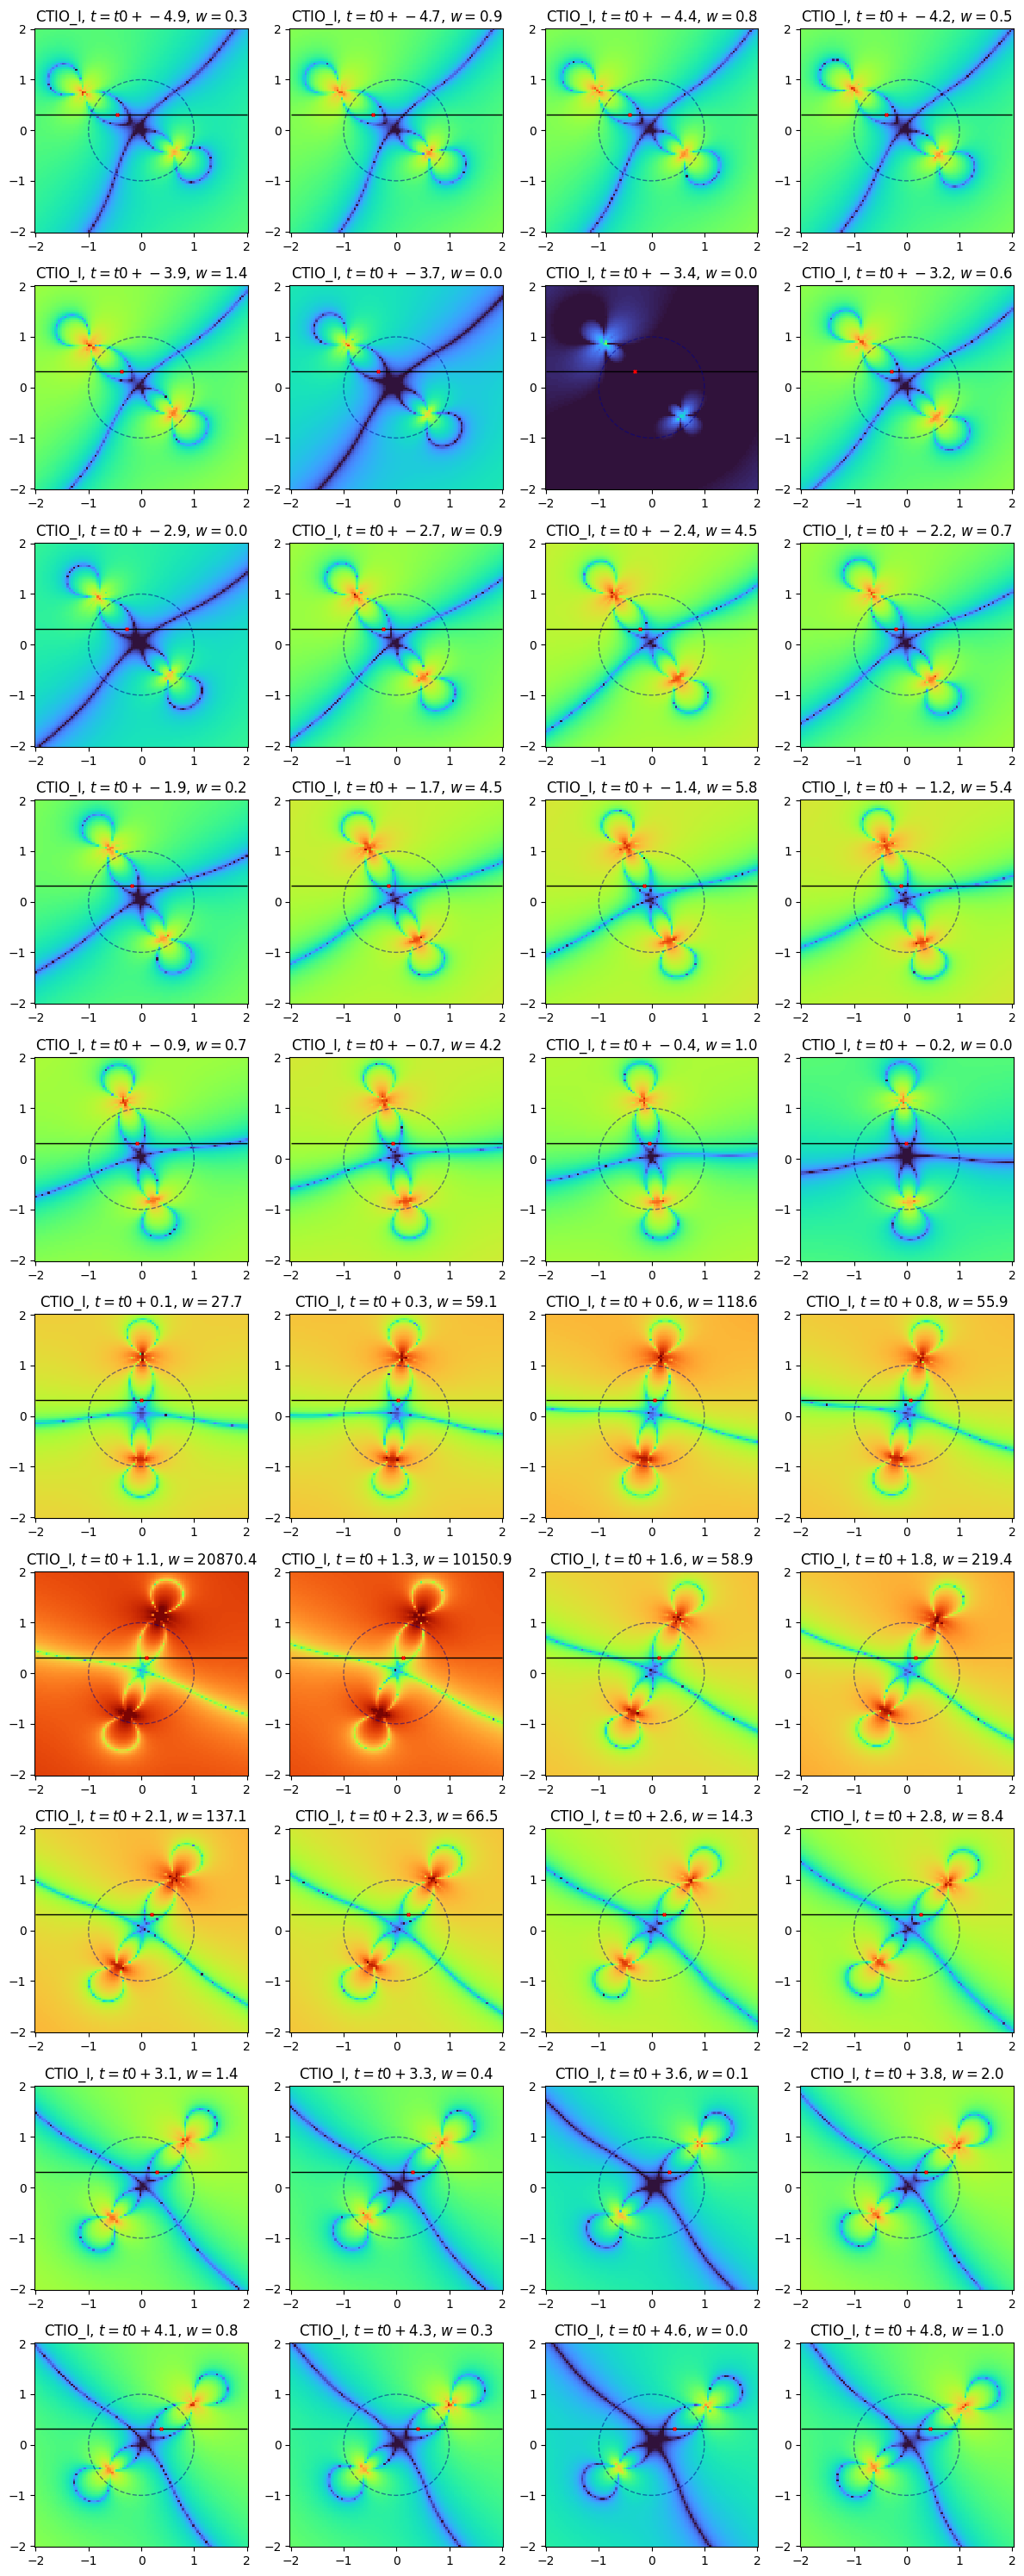

In [3]:
anomaly.create_planet_anomaly_map(
    meshgrid_corners=((-2.0,2.0),(-2.0,2.0)), 
    resolution=100)
fig_overview = anomaly.plot_overview(show=True)


/home/jakob/projects/pyLIMA-docs-revisit/my_project/planet_anomaly_map/planet_anomaly_map.py:248: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


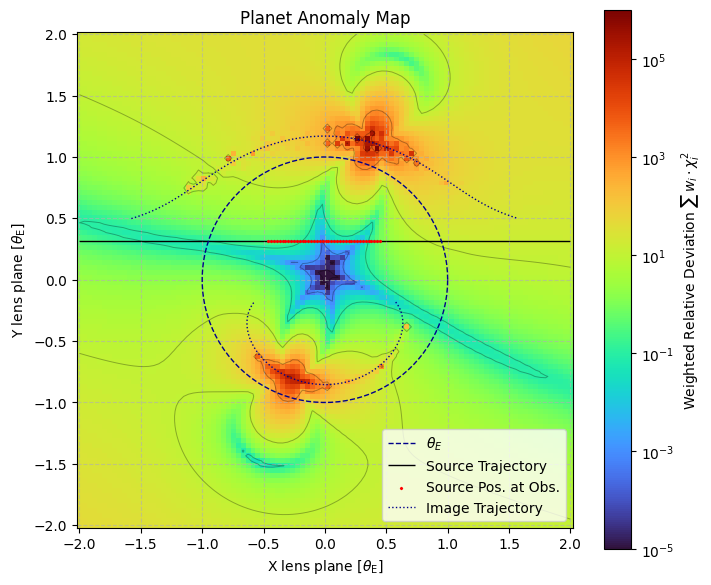

In [4]:
fig_pam = anomaly.plot_planet_anomaly_map(show=True)
meshgrid, pam = anomaly.get_planet_anomaly_map()

/home/jakob/projects/pyLIMA-docs-revisit/my_project/planet_anomaly_map/planet_anomaly_map.py:262: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


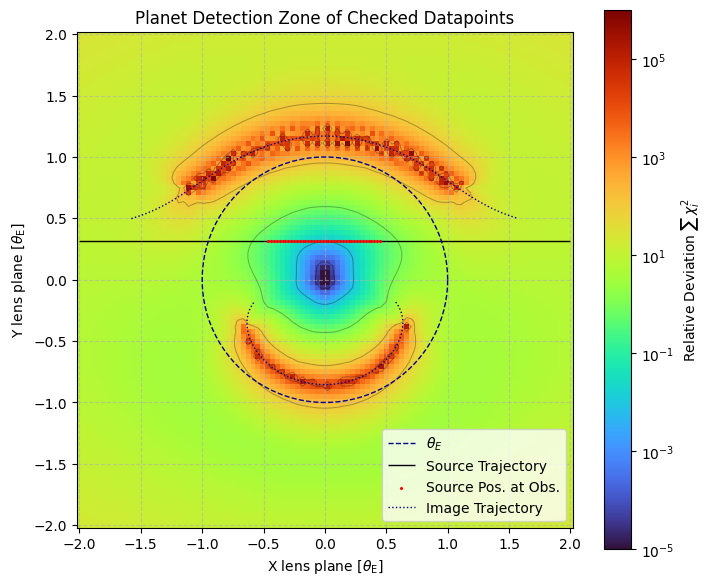

In [5]:
fig_pdzm = anomaly.plot_planet_detection_zone_map(show=True)
meshgrid, pam = anomaly.get_planet_anomaly_map()

/home/jakob/projects/pyLIMA-docs-revisit/my_project/planet_anomaly_map/planet_anomaly_map.py:343: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/home/jakob/projects/pyLIMA-docs-revisit/my_project/planet_anomaly_map/planet_anomaly_map.py:365: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  contour = plt.pcolormesh(X, Y, Z,


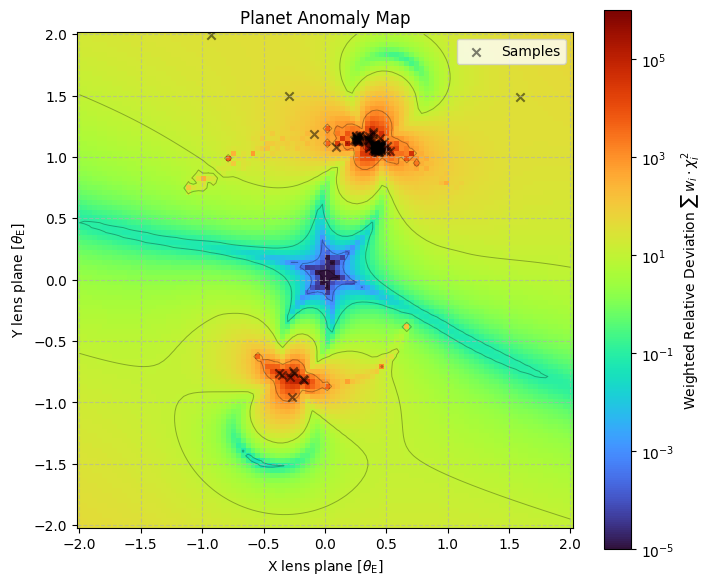

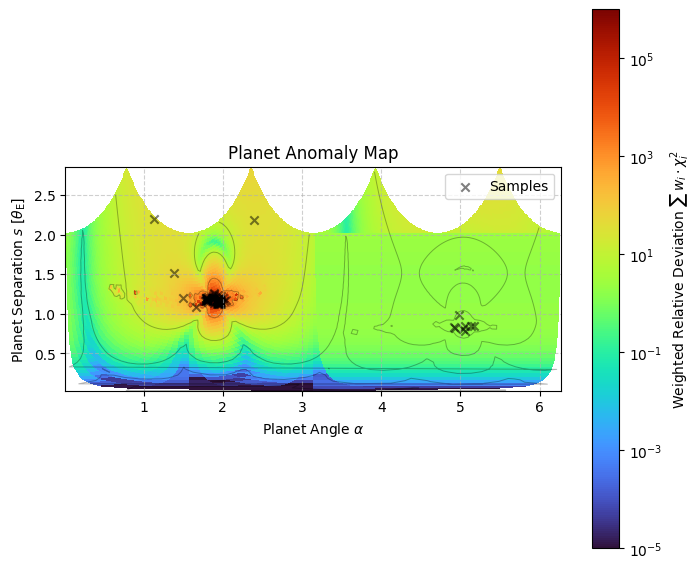

In [6]:
x_y_samples = anomaly.sample_from_planet_anomaly_map(n_samples=100)
fig_samples_xy = anomaly.create_sample_overview_plot(show=True, s_alpha_plot=False)
s_alpha_samples = anomaly.convert_x_y_to_s_alpha_samples()
fig_samples_salpha = anomaly.create_sample_overview_plot(show=True, s_alpha_plot=True)

In [7]:
### Run TRF Fits with these Initial Values

# use pspl params
t0 = anomaly.t0
u0 = anomaly.u0
te = anomaly.tE

# unpack s and alpha samples
s_samples = s_alpha_samples[:,0]
alpha_samples = s_alpha_samples[:,1]

# best fit object
best_fit = None

for i, (s, alpha) in enumerate(zip(s_samples, alpha_samples)):
    # create PSBL model
    psbl = PSBL_model.PSBLmodel(event_3)
    
    # create fit, set initial parameters, fit
    fit = TRF_fit.TRFfit(psbl, loss_function='chi2')
    fit.model_parameters_guess = [t0, u0, te, s, 0.001, alpha]
    fit.fit()

    # check chi2
    try:
        if best_fit == None or fit.fit_results[fit.loss_function] < best_fit.fit_results[best_fit.loss_function]:
            best_fit = fit
    except:
        print(f'Fit {i} failed: s={s}, alpha={alpha}\n')


initial_guess  : Initial parameters guess SUCCESS
Using guess:  [2457205.192023191, 0.315907437679635, 10.701391113352079, 1.1669105229191887, 0.001, 1.963543059200298, 9258.129341120928, 12576.123897987183]
Trust Region Reflective fit SUCCESS
best model:
OrderedDict([('t0', np.float64(2457205.2104012063)),
             ('u0', np.float64(0.3112012412378469)),
             ('tE', np.float64(10.721511978858894)),
             ('separation', np.float64(1.3013121105864411)),
             ('mass_ratio', np.float64(0.001003642025694036)),
             ('alpha', np.float64(1.8998148358744482)),
             ('fsource_CTIO_I', np.float64(10089.09630127069)),
             ('ftotal_CTIO_I', np.float64(12009.622292885422)),
             ('chi2', np.float64(107.35447833298083))])
initial_guess  : Initial parameters guess SUCCESS
Using guess:  [2457205.192023191, 0.315907437679635, 10.701391113352079, 1.1612006239439499, 0.001, 1.9182352582017015, 10547.060963105867, 11868.675054758325]
Trust Regio

Best fit choosen with a chi^2 of 107.35447828908227 and parameters:
OrderedDict([('t0', np.float64(2457205.2104011867)),
             ('u0', np.float64(0.3112012822746373)),
             ('tE', np.float64(10.72151093600836)),
             ('separation', np.float64(1.3013121543264135)),
             ('mass_ratio', np.float64(0.0010036419000569944)),
             ('alpha', np.float64(1.899814814213905)),
             ('fsource_CTIO_I', np.float64(10089.097867861386)),
             ('ftotal_CTIO_I', np.float64(12009.62244792351)),
             ('chi2', np.float64(107.35447828908227))])


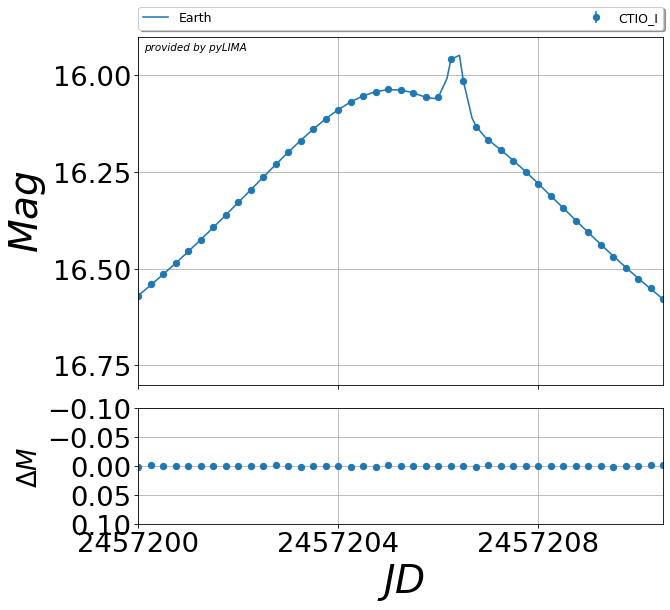

In [8]:
### Give overview over best fit
import pprint
from collections import OrderedDict 

# extract params
best_psbl_params =  OrderedDict(zip(best_fit.priors_parameters.keys(), best_fit.fit_results['best_model']))
best_psbl_params[best_fit.loss_function] = best_fit.fit_results[best_fit.loss_function]

print(f'Best fit choosen with a chi^2 of {best_fit.fit_results['chi2']} and parameters:')
pprint.pprint(best_psbl_params)

# plot
fig, _ = pyLIMA_plots.plot_lightcurves(psbl, best_fit.fit_results['best_model'])
fig.axes[0].set_xlim(2457200.0, 2457210.5)
fig.axes[0].set_ylim(16.8, 15.9)
plt.show()

In [9]:
### Compare best fit params to real values

# compare absolute values
print(f'Comparison of best of parameters:')
print('')
print(f'  simulation       |   best fit')
print(f't0:     {psbl_sim_params[0]} | {best_psbl_params['t0']}')
print(f'u0:     {psbl_sim_params[1]}      | {best_psbl_params['u0']}')
print(f'tE:     {psbl_sim_params[2]}    | {best_psbl_params['tE']}')
print(f's:      {psbl_sim_params[3]}        | {best_psbl_params['separation']}')
print(f'q:      {psbl_sim_params[4]}      | {best_psbl_params['mass_ratio']}')
print(f'alpha:  {psbl_sim_params[5]}        | {best_psbl_params['alpha']}')
print('')
print(f'chi2 of fit: {best_psbl_params['chi2']}')
print('')

# compare the sigma intervals
print('STD-intervals:')
cov = best_fit.fit_results['covariance_matrix']
unc = np.sqrt(np.diag(cov))
a = np.array(psbl_sim_params)
b = np.array(list(best_psbl_params.values())[:-1])
std = np.abs(a - b) / unc
print(f't0:     {std[0]}')
print(f'u0:     {std[1]}')
print(f'tE:     {std[2]}')
print(f's:      {std[3]}')
print(f'q:      {std[4]}')
print(f'alpha:  {std[5]}')

Comparison of best of parameters:

  simulation       |   best fit
t0:     2457205.21 | 2457205.2104011867
u0:     0.309      | 0.3112012822746373
tE:     10.7821    | 10.72151093600836
s:      1.3        | 1.3013121543264135
q:      0.001      | 0.0010036419000569944
alpha:  1.9        | 1.899814814213905

chi2 of fit: 107.35447828908227

STD-intervals:
t0:     0.3639231520412764
u0:     0.7370583045769791
tE:     0.7335700373968187
s:      0.5929408215900951
q:      0.28857782544703753
alpha:  0.24896252719548034
